### Model evaluation

The tuned CatBoost settings are tested in more detail before final training. This notebook checks where the errors come from and compares different ways to train the model while keeping the final output as `posted_rate` in dollars.

In [24]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.features import CATEGORICAL_COLUMNS, FreightPreprocessor
from src.modeling import chronological_split, model_parameters, regression_metrics

data = pd.read_csv(ROOT / "data" / "train-test.csv", parse_dates=["date"])
development, holdout = chronological_split(data, holdout_days=61)

### Selected configuration

`trial_02` had the lowest RMSE in the tuning notebook. Its depth, learning rate, and regularization are held fixed here so this notebook tests training strategies rather than repeating the same parameter search.

In [25]:
selected_config = {
    "name": "trial_02",
    "depth": 6,
    "learning_rate": 0.04,
    "l2_leaf_reg": 8.0,
    "random_strength": 0.5,
}

preprocessor = FreightPreprocessor()
x_development = preprocessor.fit_transform(development)
x_holdout = preprocessor.transform(holdout)

pd.Series({
    "development_rows": len(x_development),
    "holdout_rows": len(x_holdout),
    "features": x_development.shape[1],
}, name="value").to_frame()

,value
development_rows,38477
holdout_rows,9523
features,34


### Training helper

Each strategy stops at the iteration that performs best on the later period. Some models learn total rate and others learn rate per mile, but every prediction is converted to total dollars before RMSE and MAE are calculated.

In [26]:
def fit_catboost(y_development, y_holdout):
    model = CatBoostRegressor(**model_parameters(selected_config, iterations=2_500))
    model.fit(
        x_development,
        y_development,
        cat_features=CATEGORICAL_COLUMNS,
        eval_set=(x_holdout, y_holdout),
        early_stopping_rounds=150,
        verbose=200,
    )
    return model

### Direct posted-rate model

This model learns `posted_rate` directly and serves as the main reference. Its result is compared with models that learn a transformed version of the same business target.

In [27]:
direct_model = fit_catboost(development.posted_rate, holdout.posted_rate)
direct_prediction = np.clip(direct_model.predict(x_holdout), 1.0, None)
pd.Series(
    {
        **regression_metrics(holdout.posted_rate, direct_prediction),
        "best_iteration": direct_model.get_best_iteration() + 1,
    },
    name="direct_rate",
).round(3).to_frame()

0:	learn: 1429.9721844	test: 1479.5140573	best: 1479.5140573 (0)	total: 43ms	remaining: 1m 47s
200:	learn: 571.7245539	test: 633.2585403	best: 633.0004785 (184)	total: 9.76s	remaining: 1m 51s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 633.0004785
bestIteration = 184

Shrink model to first 185 iterations.


,direct_rate
rmse,633.000
mae,112.762
r2,0.828
best_iteration,185.000


### Error distribution

MAE describes a typical error, while RMSE rises sharply when a few errors are very large. The percentiles and largest misses show whether the overall RMSE is caused by broad weakness or a small number of unusual loads.

In [28]:
errors = holdout.copy()
errors["prediction"] = direct_prediction
errors["residual"] = errors.posted_rate - errors.prediction
errors["absolute_error"] = errors.residual.abs()
errors["squared_error"] = errors.residual ** 2
errors.absolute_error.quantile([0.50, 0.75, 0.90, 0.95, 0.99, 1.00]).round(2).to_frame("absolute_error")

,absolute_error
0.50,40.93
0.75,77.21
0.90,134.69
0.95,190.53
0.99,1540.22
1.00,16346.99


In [29]:
errors.nlargest(15, "absolute_error")[
    ["load_id", "date", "pickup", "delivery", "distance", "equipment", "posted_rate", "prediction", "absolute_error"]
].round(2)

,load_id,date,pickup,delivery,distance,equipment,posted_rate,prediction,absolute_error
40096,TR-040097,2025-09-11,Baltimore,Oklahoma City,1760.3,Reefer,20132.37,3785.38,16346.99
40171,TR-040172,2025-09-11,Montgomery,Fresno,2283.4,Dry Van,20361.89,4269.94,16091.95
43539,TR-043540,2025-10-03,Milwaukee,Bakersfield,1893.0,Dry Van,17514.11,3619.78,13894.33
46213,TR-046214,2025-10-20,Columbia,Tucson,2023.4,Flatbed,17893.17,4210.84,13682.33
47298,TR-047299,2025-10-27,Boston,Bakersfield,2979.1,Reefer,19110.30,5929.73,13180.57
40322,TR-040323,2025-09-12,Montgomery,El Paso,1639.9,Dry Van,14949.25,3294.43,11654.82
46516,TR-046517,2025-10-22,Toledo,Albuquerque,1684.3,Reefer,14784.38,3605.54,11178.84
42881,TR-042882,2025-09-29,San Antonio,Detroit,1460.5,Dry Van,13503.63,3022.15,10481.48
42149,TR-042150,2025-09-24,Grand Rapids,Lubbock,1415.5,Dry Van,13026.22,2833.41,10192.81
46366,TR-046367,2025-10-21,Bakersfield,Columbia,2251.9,Dry Van,14403.14,4257.29,10145.85


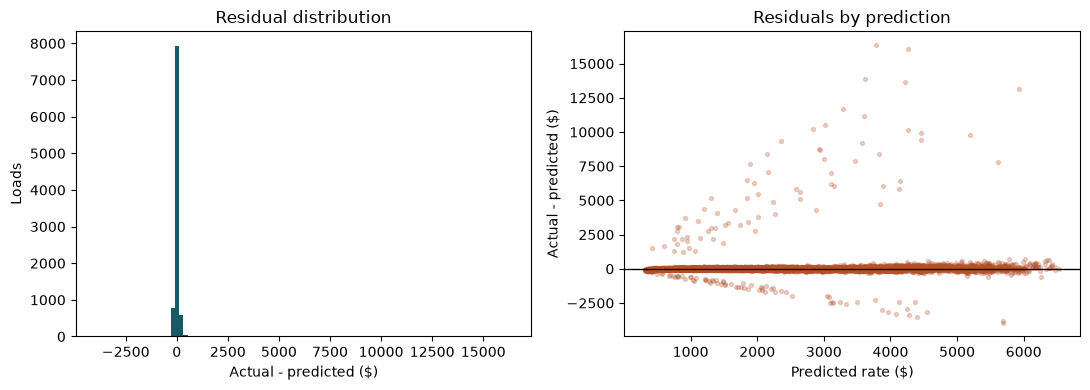

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(errors.residual, bins=100, color="#145A67")
axes[0].set(title="Residual distribution", xlabel="Actual - predicted ($)", ylabel="Loads")
axes[1].scatter(errors.prediction, errors.residual, s=8, alpha=0.25, color="#B4512A")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set(title="Residuals by prediction", xlabel="Predicted rate ($)", ylabel="Actual - predicted ($)")
plt.tight_layout()

### Segment errors

A single overall score can hide weak parts of the model. Error is therefore measured separately by equipment, trip length, target size, and whether the lane appeared in training. This identifies the types of loads that need attention.

In [31]:
def grouped_error(frame, group):
    return frame.groupby(group, observed=True).agg(
        rows=("load_id", "size"),
        mae=("absolute_error", "mean"),
        rmse=("squared_error", lambda values: np.sqrt(values.mean())),
        mean_residual=("residual", "mean"),
    ).round(2)

grouped_error(errors, "equipment")

,rows,mae,rmse,mean_residual
equipment,,,,
Dry Van,5360,109.25,654.24,38.25
Flatbed,1770,105.90,505.28,36.35
Reefer,2393,125.70,668.57,64.01


In [32]:
distance_bins = [0, 250, 500, 1_000, 2_000, np.inf]
distance_labels = ["0-250", "251-500", "501-1000", "1001-2000", "2000+"]
errors["distance_band"] = pd.cut(errors.distance, bins=distance_bins, labels=distance_labels)
grouped_error(errors, "distance_band")

,rows,mae,rmse,mean_residual
distance_band,,,,
0-250,550,51.49,118.92,-32.92
251-500,1540,57.98,271.06,28.35
501-1000,2972,76.46,366.76,32.08
1001-2000,2927,144.70,824.98,57.68
2000+,1534,199.11,921.64,86.55


In [33]:
target_p99 = development.posted_rate.quantile(0.99)
errors["target_group"] = np.where(errors.posted_rate > target_p99, "above development p99", "at or below development p99")
grouped_error(errors, "target_group")

,rows,mae,rmse,mean_residual
target_group,,,,
above development p99,101,3597.28,5703.32,3591.39
at or below development p99,9422,75.41,237.27,6.34


In [34]:
development_lanes = set(zip(development.pickup, development.delivery))
errors["lane_status"] = np.where(
    [lane in development_lanes for lane in zip(errors.pickup, errors.delivery)],
    "seen",
    "unseen",
)
grouped_error(errors, "lane_status")

,rows,mae,rmse,mean_residual
lane_status,,,,
seen,9502,112.92,633.69,44.47
unseen,21,40.52,61.22,-3.46


### Feature importance

Feature importance shows which columns CatBoost used most often to reduce error. It helps explain the model, but it does not prove that changing a feature would cause the rate to change.

In [35]:
importance = pd.DataFrame({
    "feature": preprocessor.feature_columns_,
    "importance": direct_model.get_feature_importance(),
}).sort_values("importance", ascending=False)
importance.head(15)

,feature,importance
32,log_distance,32.570481
4,distance,30.456739
26,haversine_distance,25.698423
14,equipment,5.013733
33,log_weight,0.801505
6,market_index,0.781878
5,weight,0.709692
21,month_cos,0.558291
30,midpoint_lat,0.532016
19,days_since_2025,0.479837


### Alternative targets

The required prediction is still `posted_rate`. Rate-per-mile training divides `posted_rate` by distance, lets CatBoost predict that value, and multiplies the result by distance to return to dollars. Log-rate and residual models are also tested because they reduce the influence of very large rates in different ways.

In [36]:
rpm_development = development.posted_rate / development.distance
rpm_holdout = holdout.posted_rate / holdout.distance
rpm_model = fit_catboost(rpm_development, rpm_holdout)
rpm_prediction = np.clip(rpm_model.predict(x_holdout), 0.01, None) * holdout.distance.to_numpy()

0:	learn: 0.5760107	test: 0.5938229	best: 0.5938229 (0)	total: 52ms	remaining: 2m 9s
200:	learn: 0.5019067	test: 0.5368286	best: 0.5364558 (163)	total: 9.59s	remaining: 1m 49s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 0.536455818
bestIteration = 163

Shrink model to first 164 iterations.


In [37]:
log_development = np.log1p(development.posted_rate)
log_holdout = np.log1p(holdout.posted_rate)
log_model = fit_catboost(log_development, log_holdout)
log_prediction = np.clip(np.expm1(log_model.predict(x_holdout)), 1.0, None)

0:	learn: 0.6410623	test: 0.6494090	best: 0.6494090 (0)	total: 49.7ms	remaining: 2m 4s
200:	learn: 0.1515409	test: 0.1613058	best: 0.1613058 (200)	total: 9.6s	remaining: 1m 49s
400:	learn: 0.1500136	test: 0.1612188	best: 0.1612105 (364)	total: 18.2s	remaining: 1m 35s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 0.1612001829
bestIteration = 428

Shrink model to first 429 iterations.


In [38]:
equipment_columns = ["equipment_Dry Van", "equipment_Flatbed", "equipment_Reefer"]

def baseline_matrix(frame):
    equipment = pd.get_dummies(frame.equipment, prefix="equipment", dtype=float)
    equipment = equipment.reindex(columns=equipment_columns, fill_value=0.0)
    return np.column_stack([np.ones(len(frame)), frame.distance, frame.distance ** 2, equipment])

baseline_development = baseline_matrix(development)
baseline_holdout = baseline_matrix(holdout)
baseline_coefficients, *_ = np.linalg.lstsq(
    baseline_development, development.posted_rate.to_numpy(), rcond=None
)
development_baseline_prediction = baseline_development @ baseline_coefficients
holdout_baseline_prediction = baseline_holdout @ baseline_coefficients

# CatBoost learns the remaining error after the broad distance/equipment trend.
residual_development = development.posted_rate.to_numpy() - development_baseline_prediction
residual_holdout = holdout.posted_rate.to_numpy() - holdout_baseline_prediction
residual_model = fit_catboost(residual_development, residual_holdout)
residual_prediction = np.clip(
    holdout_baseline_prediction + residual_model.predict(x_holdout),
    1.0,
    None,
)

0:	learn: 596.2024687	test: 640.0583928	best: 640.0583928 (0)	total: 51.8ms	remaining: 2m 9s
200:	learn: 568.3104430	test: 633.6347244	best: 633.6289569 (199)	total: 9.53s	remaining: 1m 48s
400:	learn: 561.8266530	test: 634.0588302	best: 633.4160514 (290)	total: 18.5s	remaining: 1m 36s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 633.4160514
bestIteration = 290

Shrink model to first 291 iterations.


In [39]:
strategy_predictions = {
    "direct_rate": direct_prediction,
    "rate_per_mile": rpm_prediction,
    "log_rate": log_prediction,
    "baseline_residual": residual_prediction,
}
strategy_results = pd.DataFrame([
    {"strategy": name, **regression_metrics(holdout.posted_rate, prediction)}
    for name, prediction in strategy_predictions.items()
]).sort_values("rmse", ignore_index=True)
strategy_results.round(3)

,strategy,rmse,mae,r2
0,rate_per_mile,632.099,104.324,0.828
1,direct_rate,633.000,112.762,0.828
2,baseline_residual,633.416,113.834,0.828
3,log_rate,638.454,120.981,0.825


### Blend

A blend averages predictions from the direct-rate model and the strongest alternative. This can reduce errors when the models make different mistakes. It is kept only when the improvement is large enough to repeat on more than one time period.

In [40]:
best_alternative = strategy_results.loc[
    strategy_results.strategy != "direct_rate", "strategy"
].iloc[0]
blend_rows = []
for direct_weight in np.linspace(0, 1, 11):
    prediction = (
        direct_weight * direct_prediction
        + (1 - direct_weight) * strategy_predictions[best_alternative]
    )
    blend_rows.append({
        "direct_weight": direct_weight,
        "alternative": best_alternative,
        **regression_metrics(holdout.posted_rate, prediction),
    })

blend_results = pd.DataFrame(blend_rows).sort_values("rmse", ignore_index=True)
blend_results.round(3)

,direct_weight,alternative,rmse,mae,r2
0,0.3,rate_per_mile,631.945,104.522,0.829
1,0.2,rate_per_mile,631.956,104.170,0.829
2,0.4,rate_per_mile,631.975,105.111,0.829
3,0.1,rate_per_mile,632.007,104.081,0.828
4,0.5,rate_per_mile,632.045,105.933,0.828
5,0.0,rate_per_mile,632.099,104.324,0.828
6,0.6,rate_per_mile,632.155,106.959,0.828
7,0.7,rate_per_mile,632.306,108.173,0.828
8,0.8,rate_per_mile,632.497,109.545,0.828
9,0.9,rate_per_mile,632.729,111.075,0.828


### Temporal backtest

A small improvement on one holdout may be luck. The same strategies are therefore tested on May-June, July-August, and September-October. A useful change should have a good average score without becoming unstable in one period.

In [41]:
def temporal_fold(train_end, validation_start, validation_end):
    dates = pd.to_datetime(data["date"], errors="raise")
    fold_development = data.loc[dates <= train_end].copy()
    fold_holdout = data.loc[dates.between(validation_start, validation_end)].copy()

    fold_preprocessor = FreightPreprocessor()
    fold_x_development = fold_preprocessor.fit_transform(fold_development)
    fold_x_holdout = fold_preprocessor.transform(fold_holdout)

    def fit_fold_model(y_development, y_holdout):
        model = CatBoostRegressor(**model_parameters(selected_config, iterations=2_500))
        model.fit(
            fold_x_development,
            y_development,
            cat_features=CATEGORICAL_COLUMNS,
            eval_set=(fold_x_holdout, y_holdout),
            early_stopping_rounds=150,
            verbose=False,
        )
        return model

    direct = fit_fold_model(fold_development.posted_rate, fold_holdout.posted_rate)
    direct_rate = np.clip(direct.predict(fold_x_holdout), 1.0, None)

    development_rpm = fold_development.posted_rate / fold_development.distance
    holdout_rpm = fold_holdout.posted_rate / fold_holdout.distance
    rpm = fit_fold_model(development_rpm, holdout_rpm)
    rpm_rate = np.clip(rpm.predict(fold_x_holdout), 0.01, None) * fold_holdout.distance.to_numpy()
    blended_rate = 0.30 * direct_rate + 0.70 * rpm_rate

    fold_name = f"{validation_start:%Y-%m} to {validation_end:%Y-%m}"
    return [
        {"fold": fold_name, "strategy": "direct_rate", **regression_metrics(fold_holdout.posted_rate, direct_rate)},
        {"fold": fold_name, "strategy": "rate_per_mile", **regression_metrics(fold_holdout.posted_rate, rpm_rate)},
        {"fold": fold_name, "strategy": "30_70_blend", **regression_metrics(fold_holdout.posted_rate, blended_rate)},
    ]

In [42]:
folds = [
    (pd.Timestamp("2025-04-30"), pd.Timestamp("2025-05-01"), pd.Timestamp("2025-06-30")),
    (pd.Timestamp("2025-06-30"), pd.Timestamp("2025-07-01"), pd.Timestamp("2025-08-31")),
    (pd.Timestamp("2025-08-31"), pd.Timestamp("2025-09-01"), pd.Timestamp("2025-10-31")),
]
backtest_results = pd.DataFrame([
    row
    for fold in folds
    for row in temporal_fold(*fold)
])
backtest_results.round(3)

,fold,strategy,rmse,mae,r2
0,2025-05 to 2025-06,direct_rate,642.737,133.188,0.827
1,2025-05 to 2025-06,rate_per_mile,635.402,116.455,0.831
2,2025-05 to 2025-06,30_70_blend,636.299,117.557,0.831
3,2025-07 to 2025-08,direct_rate,628.462,166.978,0.822
4,2025-07 to 2025-08,rate_per_mile,630.043,150.077,0.821
5,2025-07 to 2025-08,30_70_blend,627.901,151.043,0.823
6,2025-09 to 2025-10,direct_rate,633.000,112.762,0.828
7,2025-09 to 2025-10,rate_per_mile,632.099,104.324,0.828
8,2025-09 to 2025-10,30_70_blend,631.945,104.522,0.829


In [43]:
backtest_results.groupby("strategy")[["rmse", "mae", "r2"]].agg(["mean", "std"]).round(3)

rmse             mae             r2       
                  mean    std     mean     std   mean    std
strategy                                                    
30_70_blend    632.048  4.200  124.374  23.998  0.827  0.004
direct_rate    634.733  7.294  137.643  27.381  0.826  0.003
rate_per_mile  632.515  2.703  123.619  23.703  0.827  0.005

### Extreme-rate diagnosis

The rate-per-mile distribution has a clear empty region: normal values end near $3, while the unusual group begins above $5. A $4 threshold separates these groups without labeling ordinary high rates as extreme. The split is used for diagnosis, not as automatic proof that a row is wrong.

In [44]:
from catboost import CatBoostClassifier

def load_fresh_fold():
    raw = pd.read_csv(ROOT / "data" / "train-test.csv", parse_dates=["date"])
    fold_development, fold_holdout = chronological_split(raw, holdout_days=61)
    fold_preprocessor = FreightPreprocessor()
    fold_x_development = fold_preprocessor.fit_transform(fold_development)
    fold_x_holdout = fold_preprocessor.transform(fold_holdout)
    return fold_development, fold_holdout, fold_x_development, fold_x_holdout

fresh_development, fresh_holdout, fresh_x_development, fresh_x_holdout = load_fresh_fold()
development_rpm = fresh_development.posted_rate / fresh_development.distance
holdout_rpm = fresh_holdout.posted_rate / fresh_holdout.distance
development_extreme = development_rpm.gt(4).astype(int)
holdout_extreme = holdout_rpm.gt(4).astype(int)

pd.DataFrame({
    "development": [len(development_extreme), int(development_extreme.sum()), development_extreme.mean() * 100],
    "holdout": [len(holdout_extreme), int(holdout_extreme.sum()), holdout_extreme.mean() * 100],
}, index=["rows", "extreme_rows", "extreme_pct"]).round(3)

,development,holdout
rows,38477.000,9523.000
extreme_rows,267.000,73.000
extreme_pct,0.694,0.767


### Spike predictability

A separate classifier tries to identify extreme rates using only information available before pricing. AUC measures how well it ranks extreme rows: 0.5 is no better than guessing, while 1.0 is perfect. A result near 0.5 means the provided features cannot tell us which future loads will spike.

In [45]:
spike_classifier = CatBoostClassifier(
    loss_function="Logloss",
    eval_metric="AUC",
    iterations=1_500,
    depth=6,
    learning_rate=0.04,
    l2_leaf_reg=8.0,
    auto_class_weights="Balanced",
    random_seed=42,
    allow_writing_files=False,
    verbose=200,
)
spike_classifier.fit(
    fresh_x_development,
    development_extreme,
    cat_features=CATEGORICAL_COLUMNS,
    eval_set=(fresh_x_holdout, holdout_extreme),
    early_stopping_rounds=150,
)
spike_probability = spike_classifier.predict_proba(fresh_x_holdout)[:, 1]

0:	test: 0.4890527	best: 0.4890527 (0)	total: 212ms	remaining: 5m 17s
200:	test: 0.5146061	best: 0.5224455 (114)	total: 20.5s	remaining: 2m 12s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 0.5224454592
bestIteration = 114

Shrink model to first 115 iterations.


In [46]:
def rank_auc(actual, score):
    actual = np.asarray(actual, dtype=int)
    ranks = pd.Series(score).rank(method="average").to_numpy()
    positives = actual.sum()
    negatives = len(actual) - positives
    return (ranks[actual == 1].sum() - positives * (positives + 1) / 2) / (positives * negatives)

pd.Series({
    "auc": rank_auc(holdout_extreme, spike_probability),
    "best_iteration": spike_classifier.get_best_iteration() + 1,
    "holdout_extreme_rows": int(holdout_extreme.sum()),
}, name="spike_classifier").round(3).to_frame()

,spike_classifier
auc,0.522
best_iteration,115.000
holdout_extreme_rows,73.000


### Outlier treatment comparison

These trials test whether extreme target rows should be kept, removed, limited, or given extra weight. Every trial reloads the original CSV and refits preprocessing, so one experiment cannot change the next. The choice is based on later-period error rather than assuming that every unusual value is bad data.

In [47]:
experiment_config = {
    "name": "trial_02",
    "depth": 6,
    "learning_rate": 0.04,
    "l2_leaf_reg": 8.0,
    "random_strength": 0.5,
}

def run_outlier_trial(name, mode="keep", extreme_weight=1.0):
    trial_development, trial_holdout, trial_x_development, trial_x_holdout = load_fresh_fold()
    trial_development_rpm = trial_development.posted_rate / trial_development.distance
    trial_holdout_rpm = trial_holdout.posted_rate / trial_holdout.distance
    extreme_mask = trial_development_rpm.gt(4)

    training_mask = pd.Series(True, index=trial_development.index)
    training_target = trial_development_rpm.copy()
    sample_weight = np.ones(len(trial_development))

    if mode == "remove":
        training_mask = ~extreme_mask
    elif mode == "cap":
        training_target = training_target.clip(upper=4)
    elif mode == "weight":
        sample_weight[extreme_mask.to_numpy()] = extreme_weight

    model = CatBoostRegressor(**model_parameters(experiment_config, iterations=2_500))
    fit_arguments = {}
    if mode == "weight":
        fit_arguments["sample_weight"] = sample_weight[training_mask.to_numpy()]
    model.fit(
        trial_x_development.loc[training_mask],
        training_target.loc[training_mask],
        cat_features=CATEGORICAL_COLUMNS,
        eval_set=(trial_x_holdout, trial_holdout_rpm),
        early_stopping_rounds=150,
        verbose=False,
        **fit_arguments,
    )

    prediction = np.clip(model.predict(trial_x_holdout), 0.01, None) * trial_holdout.distance.to_numpy()
    actual = trial_holdout.posted_rate.to_numpy()
    normal_mask = trial_holdout_rpm.le(4).to_numpy()
    extreme_holdout_mask = ~normal_mask
    return {
        "strategy": name,
        **regression_metrics(actual, prediction),
        "normal_rmse": regression_metrics(actual[normal_mask], prediction[normal_mask])["rmse"],
        "extreme_rmse": regression_metrics(actual[extreme_holdout_mask], prediction[extreme_holdout_mask])["rmse"],
        "mean_residual": float(np.mean(actual - prediction)),
        "best_iteration": model.get_best_iteration() + 1,
    }

In [48]:
outlier_trials = [
    ("keep_all", "keep", 1.0),
    ("remove_rpm_above_4", "remove", 1.0),
    ("cap_rpm_at_4", "cap", 1.0),
    ("extreme_weight_2", "weight", 2.0),
    ("extreme_weight_5", "weight", 5.0),
    ("extreme_weight_10", "weight", 10.0),
]
outlier_results = pd.DataFrame([
    run_outlier_trial(name, mode, weight)
    for name, mode, weight in outlier_trials
]).sort_values("rmse", ignore_index=True)
outlier_results.round(3)

,strategy,rmse,mae,r2,normal_rmse,extreme_rmse,mean_residual,best_iteration
0,extreme_weight_2,631.392,120.021,0.829,186.604,6891.862,-6.196,112
1,keep_all,632.099,104.324,0.828,170.780,6953.162,48.016,164
2,cap_rpm_at_4,634.644,111.425,0.827,172.106,6979.125,77.484,1313
3,remove_rpm_above_4,637.569,119.847,0.825,176.233,7000.534,91.667,576
4,extreme_weight_5,664.430,240.199,0.810,307.815,6732.358,-151.019,66
5,extreme_weight_10,713.537,307.630,0.781,414.929,6643.070,-206.257,383


### Loss and distance weighting

The final comparison tests standard RMSE, robust losses, distance weighting, and time-ordered CatBoost across all three periods. Distance weighting gives longer loads more influence because a small per-mile mistake becomes a larger dollar mistake on a long trip. Huber and MAE reduce the influence of extreme targets, so the results show whether that improves future dollar predictions.

In [49]:
from catboost import Pool

final_strategies = [
    {"strategy": "direct_rmse", "target": "direct", "loss": "RMSE", "weight": "none"},
    {"strategy": "direct_huber_300", "target": "direct", "loss": "Huber:delta=300", "weight": "none"},
    {"strategy": "rpm_rmse", "target": "rpm", "loss": "RMSE", "weight": "none"},
    {"strategy": "rpm_huber_0.2", "target": "rpm", "loss": "Huber:delta=0.2", "weight": "none"},
    {"strategy": "rpm_mae", "target": "rpm", "loss": "MAE", "weight": "none"},
    {"strategy": "rpm_rmse_distance", "target": "rpm", "loss": "RMSE", "weight": "distance"},
    {"strategy": "rpm_rmse_distance_squared", "target": "rpm", "loss": "RMSE", "weight": "distance_squared"},
    {"strategy": "rpm_rmse_ordered", "target": "rpm", "loss": "RMSE", "weight": "none", "ordered": True},
]

In [50]:
def normalized_weight(distance, mode):
    values = np.asarray(distance, dtype=float)
    if mode == "distance":
        values = values
    elif mode == "distance_squared":
        values = values ** 2
    else:
        return None
    return values / values.mean()


def run_final_fold(train_end, validation_start, validation_end, strategy):
    raw = pd.read_csv(ROOT / "data" / "train-test.csv", parse_dates=["date"])
    raw = raw.sort_values("date", kind="stable").reset_index(drop=True)
    fold_development = raw.loc[raw.date <= train_end].copy()
    fold_holdout = raw.loc[raw.date.between(validation_start, validation_end)].copy()

    fold_preprocessor = FreightPreprocessor()
    fold_x_development = fold_preprocessor.fit_transform(fold_development)
    fold_x_holdout = fold_preprocessor.transform(fold_holdout)

    if strategy["target"] == "rpm":
        y_development = fold_development.posted_rate / fold_development.distance
        y_holdout = fold_holdout.posted_rate / fold_holdout.distance
        # Weighted validation RMSE selects iterations using error in dollars.
        validation_weight = normalized_weight(fold_holdout.distance, "distance_squared")
    else:
        y_development = fold_development.posted_rate
        y_holdout = fold_holdout.posted_rate
        validation_weight = None

    training_weight = normalized_weight(fold_development.distance, strategy["weight"])
    train_pool = Pool(
        fold_x_development,
        label=y_development,
        cat_features=CATEGORICAL_COLUMNS,
        weight=training_weight,
    )
    validation_pool = Pool(
        fold_x_holdout,
        label=y_holdout,
        cat_features=CATEGORICAL_COLUMNS,
        weight=validation_weight,
    )

    parameters = {
        "loss_function": strategy["loss"],
        "eval_metric": "RMSE",
        "iterations": 2_500,
        "depth": selected_config["depth"],
        "learning_rate": selected_config["learning_rate"],
        "l2_leaf_reg": selected_config["l2_leaf_reg"],
        "random_strength": selected_config["random_strength"],
        "bootstrap_type": "Bernoulli",
        "subsample": 0.85,
        "random_seed": 42,
        "allow_writing_files": False,
        "thread_count": -1,
    }
    if strategy.get("ordered", False):
        parameters.update({"boosting_type": "Ordered", "has_time": True})

    model = CatBoostRegressor(**parameters)
    model.fit(
        train_pool,
        eval_set=validation_pool,
        early_stopping_rounds=150,
        verbose=False,
    )
    prediction = np.clip(model.predict(fold_x_holdout), 0.01, None)
    if strategy["target"] == "rpm":
        prediction = prediction * fold_holdout.distance.to_numpy()

    actual = fold_holdout.posted_rate.to_numpy()
    holdout_rpm = actual / fold_holdout.distance.to_numpy()
    normal = holdout_rpm <= 4
    return {
        "fold": f"{validation_start:%Y-%m} to {validation_end:%Y-%m}",
        "strategy": strategy["strategy"],
        **regression_metrics(actual, prediction),
        "normal_rmse": regression_metrics(actual[normal], prediction[normal])["rmse"],
        "extreme_rmse": regression_metrics(actual[~normal], prediction[~normal])["rmse"],
        "mean_residual": float(np.mean(actual - prediction)),
        "best_iteration": model.get_best_iteration() + 1,
    }

In [51]:
final_trial_results = pd.DataFrame([
    run_final_fold(*fold, strategy)
    for fold in folds
    for strategy in final_strategies
])
final_trial_results.round(3)

,fold,strategy,rmse,mae,r2,normal_rmse,extreme_rmse,mean_residual,best_iteration
0,2025-05 to 2025-06,direct_rmse,642.737,133.188,0.827,207.617,7489.924,66.650,373
1,2025-05 to 2025-06,direct_huber_300,638.088,141.323,0.830,206.057,7435.993,78.413,1196
2,2025-05 to 2025-06,rpm_rmse,635.118,116.765,0.831,189.689,7462.974,70.247,202
3,2025-05 to 2025-06,rpm_huber_0.2,641.839,153.560,0.828,243.846,7311.815,8.675,501
4,2025-05 to 2025-06,rpm_mae,651.959,172.694,0.822,249.843,7416.243,92.257,1045
5,2025-05 to 2025-06,rpm_rmse_distance,633.604,114.289,0.832,190.710,7439.530,55.382,231
6,2025-05 to 2025-06,rpm_rmse_distance_squared,640.235,140.410,0.829,213.555,7432.109,59.162,214
7,2025-05 to 2025-06,rpm_rmse_ordered,633.772,117.042,0.832,191.443,7438.862,57.415,340
8,2025-07 to 2025-08,direct_rmse,628.462,166.978,0.822,216.802,6986.918,-73.541,100
9,2025-07 to 2025-08,direct_huber_300,992.387,383.015,0.557,776.120,7362.689,118.837,187


In [52]:
final_trial_summary = (
    final_trial_results.groupby("strategy")
    .agg(
        rmse_mean=("rmse", "mean"),
        rmse_std=("rmse", "std"),
        mae_mean=("mae", "mean"),
        normal_rmse_mean=("normal_rmse", "mean"),
        extreme_rmse_mean=("extreme_rmse", "mean"),
        mean_residual=("mean_residual", "mean"),
        mean_iteration=("best_iteration", "mean"),
    )
    .sort_values("rmse_mean")
)
final_trial_summary.round(3)

,rmse_mean,rmse_std,mae_mean,normal_rmse_mean,extreme_rmse_mean,mean_residual,mean_iteration
strategy,,,,,,,
rpm_rmse_distance,632.068,1.507,123.243,193.351,7132.980,23.551,137.667
rpm_rmse_ordered,632.116,1.444,128.585,197.508,7116.011,3.811,193.000
rpm_rmse,632.344,2.578,124.338,194.148,7133.345,17.962,157.333
direct_rmse,634.733,7.294,137.643,199.980,7141.804,12.492,219.333
rpm_rmse_distance_squared,634.924,4.759,136.747,201.792,7136.026,35.915,121.333
rpm_mae,639.955,10.423,149.365,215.505,7137.761,52.320,422.000
rpm_huber_0.2,761.702,131.163,223.567,455.065,7084.274,-22.955,1693.667
direct_huber_300,770.556,193.317,229.353,428.290,7258.407,94.241,1294.333


### Final choice

The final model still predicts `posted_rate`. Internally, it learns rate per mile with standard RMSE and gives longer loads more training weight. The predicted rate per mile is multiplied by distance to produce the submitted dollar rate.

This strategy had the lowest average RMSE across the three time periods and remained stable between them. Robust losses and stronger distance weighting were rejected because they increased both typical error and overall error.